In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shuvoalok/ck-dataset")

print("Path to dataset files:", path)

100%|██████████| 1.80M/1.80M [00:00<00:00, 142MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/shuvoalok/ck-dataset/versions/1


Found 981 files belonging to 7 classes.
Using 785 files for training.
Found 981 files belonging to 7 classes.
Using 196 files for validation.
Detected classes: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.3312 - loss: 1.8246
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.4153 - loss: 1.6417
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.6178 - loss: 1.2033
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7363 - loss: 0.7817
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8471 - loss: 0.5091
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8520 - loss: 0.4778


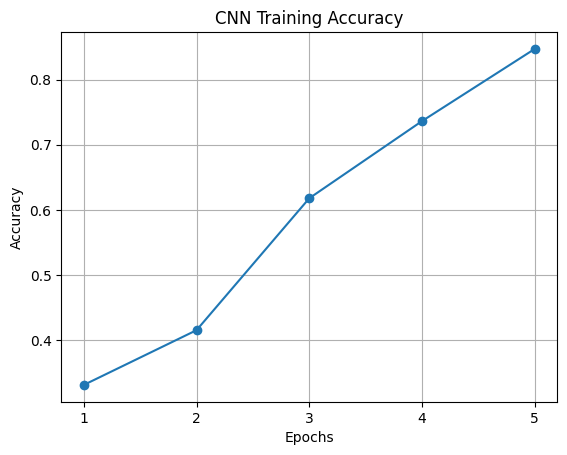

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# Load training dataset (80%)
train = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Load testing/validation dataset (20%)
test = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Identify number of classes automatically
num_classes = len(train.class_names)
print("Detected classes:", train.class_names)

# Build CNN model
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(48, 48, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(train, epochs=5)

# Evaluate model
model.evaluate(test)

# Plot training accuracy
plt.plot(history.history['accuracy'], marker='o')

plt.title('CNN Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(range(5), range(1, 6))
plt.grid(True)

plt.show()